In [61]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import json

### Read AIA results

In [62]:
df = pd.read_csv("../vine_evaluation/inference/reg_coeff.csv")

In [63]:
df.head()

,Unnamed: 0,genModel,truncLvl,sa,tid,gameID,synDataID,coefficient,value
0,0,CVCDA,1,x1,ID84,0,0,x2,0.002558
1,1,CVCDA,1,x1,ID84,0,0,x3,-0.031352
2,2,CVCDA,1,x1,ID84,0,0,x4,0.009242
3,3,CVCDA,1,x1,ID84,0,0,x5,0.034634
4,4,CVCDA,1,x1,ID84,0,0,x6,-0.055396


In [64]:
df.genModel.unique()

array(['CVCDA', 'IMRV(0.25)', 'IMRV(0.5)', 'IMRV(0.75)',
       'CvineSensitive(5)', 'Cvine', 'CVCDASensitive'], dtype=object)

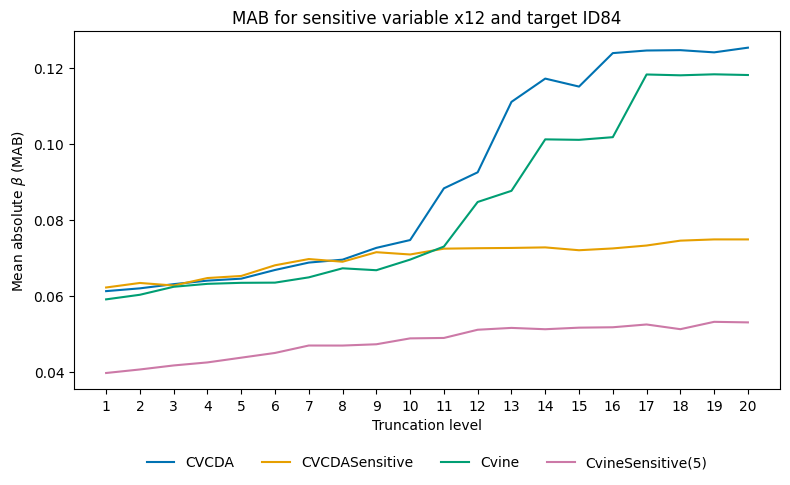

In [65]:
maxTrunc = df.truncLvl.max()
sa = "x12"
tid = "ID84"

fig, ax = plt.subplots(figsize=(8, 5))

gmList = ["CVCDA", "CVCDASensitive", "Cvine", "CvineSensitive(5)"]
cols = ["#0072B2", "#E69F00", "#009E73", "#CC79A7"]

for gm, col in zip(gmList, cols):
    sub = df.loc[(df["genModel"] == gm) & (df["tid"] == tid) & (df["sa"] == sa),:]

    sub.groupby("truncLvl")["value"].apply(lambda x: x.abs().mean()).plot(ax=ax, label=gm, color=col,)

ax.set_xticks(sub.truncLvl.unique(), sub.truncLvl.unique())
ax.set_xlabel("Truncation level")
ax.set_ylabel(r"Mean absolute $\beta$ (MAB)")
ax.set_title(f"MAB for sensitive variable {sa} and target {tid}")
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.15), ncol=4, frameon=False)

fig.tight_layout()
plt.show()

### Read utility evaluation results

In [68]:
with open("../vine_evaluation/utility/utility_metrics_simulated_data_tvinesynth.json") as f:
    obj = json.load(f)

In [69]:
obj.keys()

dict_keys(['Raw', 'CVCDA', 'IMRV(0.25)', 'IMRV(0.5)', 'IMRV(0.75)', 'CvineSensitive(5)', 'Cvine', 'CVCDASensitive'])

In [70]:
df = pd.DataFrame(None, columns=["type", "trunc_lvl", "AUC-ROC", "Accuracy"])

In [71]:
raw_df = pd.DataFrame(obj["Raw"])
raw_df["type"] = "Raw"
raw_df["trunc_lvl"] = np.nan

df = pd.concat([df, raw_df[["type", "trunc_lvl", "AUC-ROC", "Accuracy"]]], ignore_index=True)

/tmp/ipykernel_2858808/3265670226.py:5: FutureWarning: The behavior of DataFrame concatenation with empty or all-NA entries is deprecated. In a future version, this will no longer exclude empty or all-NA columns when determining the result dtypes. To retain the old behavior, exclude the relevant entries before the concat operation.
  df = pd.concat([df, raw_df[["type", "trunc_lvl", "AUC-ROC", "Accuracy"]]], ignore_index=True)


In [73]:
obj["CVCDASensitive"]

{'1': {'Accuracy': [0.71,
   0.69,
   0.722,
   0.766,
   0.706,
   0.726,
   0.712,
   0.7,
   0.728,
   0.734,
   0.708,
   0.686,
   0.694,
   0.708,
   0.716,
   0.746,
   0.736,
   0.686,
   0.676,
   0.708,
   0.692,
   0.702,
   0.71,
   0.696,
   0.7,
   0.688,
   0.686,
   0.764,
   0.672,
   0.664,
   0.678,
   0.652,
   0.718,
   0.67,
   0.706,
   0.716,
   0.742,
   0.69,
   0.674,
   0.712,
   0.728,
   0.724,
   0.742,
   0.674,
   0.758,
   0.744,
   0.642,
   0.716,
   0.72,
   0.696],
  'AUC-ROC': [0.7815349114908586,
   0.7563556608606556,
   0.7772577444956477,
   0.829561470946249,
   0.7786700957556936,
   0.8022293707189041,
   0.7686160406547075,
   0.7795171451930939,
   0.802051282051282,
   0.8068021654173874,
   0.7393078289252628,
   0.774485219655688,
   0.767340439152423,
   0.7799859190988223,
   0.7871554487179486,
   0.8056970337625728,
   0.7958159196810298,
   0.7578044125258798,
   0.7590532146516394,
   0.7914259653390089,
   0.7596566180235534,
  

In [74]:
rows = []
for model in ['CVCDA', 'CVCDASensitive', 'CvineSensitive(5)', 'Cvine']:
    for trunc_lvl, metrics in obj[model].items():
        n = len(metrics["Accuracy"])
        rows.append(pd.DataFrame({
            "type": [model] * n,
            "trunc_lvl": [int(trunc_lvl)] * n,
            "AUC-ROC": metrics["AUC-ROC"],
            "Accuracy": metrics["Accuracy"],
        }))

    model_df = pd.concat(rows, ignore_index=True)
    
    df = pd.concat([df, model_df], ignore_index=True)

In [75]:
df.type.unique()

array(['Raw', 'CVCDA', 'CVCDASensitive', 'CvineSensitive(5)', 'Cvine'],
      dtype=object)

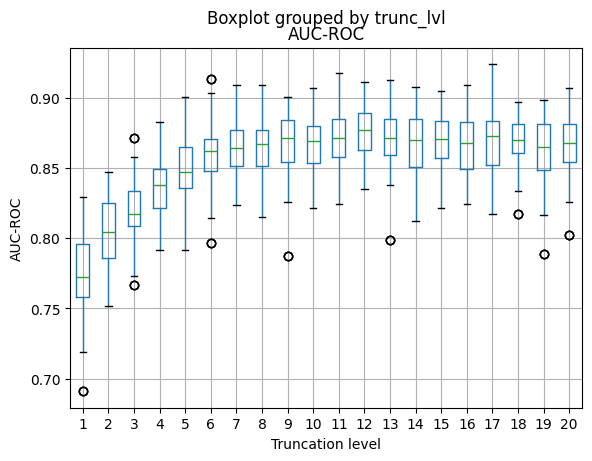

In [77]:
df.loc[df["type"]=="CVCDASensitive",].boxplot(column="AUC-ROC", by="trunc_lvl", 
                                     xlabel="Truncation level", ylabel="AUC-ROC")
plt.show()